In [ ]:
import kagglehub as kh
from pathlib import Path
import pandas as pd
file_path = kh.dataset_download("apollo2506/eurosat-dataset")
dataset_dir=Path(file_path)
records=[]
for file in dataset_dir.rglob("*.jpg"):
  records.append({
    "filepath": str(file),
    "label": file.parent.name
    })
df = pd.DataFrame(records)

Using Colab cache for faster access to the 'eurosat-dataset' dataset.


In [ ]:
print("total images:\n", len(df))
print("distribution:\n")
print(df['label'].value_counts())

total images:
 27000
distribution:

label
SeaLake                 3000
Residential             3000
Forest                  3000
HerbaceousVegetation    3000
AnnualCrop              3000
Highway                 2500
River                   2500
Industrial              2500
PermanentCrop           2500
Pasture                 2000
Name: count, dtype: int64


In [ ]:
import torch
import torch.fx
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import train_test_split
label_to_index = {name:i for i,name in enumerate(df['label'].unique())}
index_to_label = {i:name for i,name in enumerate(df['label'].unique())}
df['label_index']=df['label'].map(label_to_index)

#80/10/10 train validate test

train_df, temp = train_test_split(df ,test_size=0.2 ,random_state=67, stratify=df['label_index'])
val_df, test_df = train_test_split(temp, test_size=0.5, random_state=210309, stratify=temp['label_index'])

class euroSAT(Dataset):
  def __init__(self, dataframe, Transform=None):
    self.dataframe = dataframe.reset_index(drop=True)
    self.transform = Transform

  def __len__(self):
    return len(self.dataframe)

  def __getitem__(self,index):
    img_path = self.dataframe.loc[index, 'filepath'] #lazy loading
    label = self.dataframe.loc[index, 'label_index']
    image = Image.open(img_path).convert('RGB') #dataset says rgb but just in case

    if self.transform: image=self.transform(image)

    return image, label

"""transformations. Normalized to match imageNET rgb values (0.485, 0.456, 0.406)
  and standard deviation values (0.229, 0.224, 0.225) resulting in mean=0 and std_dev=1"""

train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(degrees=90),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

eval_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])


train_loader = DataLoader(euroSAT(train_df, train_transforms),
                          batch_size=64, shuffle=True, num_workers=2)

val_loader = DataLoader(euroSAT(val_df, eval_transforms),
                        batch_size=64, shuffle=False, num_workers=2)

test_loader = DataLoader(euroSAT(test_df, eval_transforms),
                         batch_size=64, shuffle=False, num_workers=2)

print(f"Batches: {len(train_loader)} train | {len(val_loader)} val | {len(test_loader)} test")

Batches: 338 train | 43 val | 43 test


In [ ]:
#setup
import torch.nn as nn
from torchvision import models
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
#num_ftrs=512 hardcoded for resnet18 next line is dynamic allocation
num_ftrs=model.fc.in_features
model.fc=nn.Linear(num_ftrs, len(label_to_index))
model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)




Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s]


In [ ]:
#training run with gpu
import time
epochs=10 #runs
for epoch in range(epochs):
  start_time = time.time()

  model.train()
  running_loss=0.0
  running_corrects=0
  for inputs, labels in train_loader:
    inputs, labels=inputs.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs=model(inputs)
    loss=criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    logit, predictions = torch.max(outputs, 1)
    running_loss += loss.item() * inputs.size(0)
    running_corrects += torch.sum(predictions == labels.data)

  train_loss = running_loss / len(train_loader.dataset)
  train_acc = running_corrects.double() / len(train_loader.dataset)

  #validation

  model.eval()
  val_loss=0.0
  val_corrects=0
  with torch.no_grad():
    for inputs, labels in val_loader:
      inputs, labels=inputs.to(device), labels.to(device)
      outputs=model(inputs)
      loss=criterion(outputs, labels)
      logit, predictions = torch.max(outputs, 1)
      val_loss += loss.item() * inputs.size(0)
      val_corrects += torch.sum(predictions == labels.data)

  val_loss=val_loss/len(val_loader.dataset)
  val_acc=val_corrects.double()/len(val_loader.dataset)

  epoch_time=time.time()
  print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
  print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}")
  print(f"Time: {epoch_time:.0f}s\n")



Train Loss: 0.4978 | Train Acc: 0.8404
Val Loss:   0.2881 | Val Acc:   0.9048
Time: 1792521067s

Train Loss: 0.3038 | Train Acc: 0.8981
Val Loss:   0.2602 | Val Acc:   0.9093
Time: 1792521090s

Train Loss: 0.2541 | Train Acc: 0.9162
Val Loss:   0.2419 | Val Acc:   0.9167
Time: 1792521113s

Train Loss: 0.2423 | Train Acc: 0.9206
Val Loss:   0.3212 | Val Acc:   0.9044
Time: 1792521137s

Train Loss: 0.2151 | Train Acc: 0.9275
Val Loss:   0.2500 | Val Acc:   0.9200
Time: 1792521160s

Train Loss: 0.1962 | Train Acc: 0.9348
Val Loss:   0.2404 | Val Acc:   0.9267
Time: 1792521183s

Train Loss: 0.1921 | Train Acc: 0.9353
Val Loss:   0.5220 | Val Acc:   0.8326
Time: 1792521207s

Train Loss: 0.1798 | Train Acc: 0.9408
Val Loss:   0.2448 | Val Acc:   0.9215
Time: 1792521230s

Train Loss: 0.1844 | Train Acc: 0.9390
Val Loss:   0.2146 | Val Acc:   0.9307
Time: 1792521254s

Train Loss: 0.1607 | Train Acc: 0.9453
Val Loss:   0.1698 | Val Acc:   0.9419
Time: 1792521278s



In [ ]:
#testing
model.eval()
test_loss=0.0
test_corrects=0
with torch.no_grad():
  for inputs, labels in test_loader:
    inputs, labels=inputs.to(device), labels.to(device)
    outputs=model(inputs)
    loss=criterion(outputs, labels)
    logit, predictions = torch.max(outputs,1)
    test_loss += loss.item() * inputs.size(0)
    test_corrects += torch.sum(predictions == labels.data)
final_loss=test_loss/len(test_loader.dataset)
final_acc=test_corrects.double()/len(test_loader.dataset)
print(f"Test Loss: {final_loss:.4f} | Test Acc: {final_acc:.4f}")

Test Loss: 0.1687 | Test Acc: 0.9426


Classification Report:
                      precision    recall  f1-score   support

             SeaLake       0.97      0.98      0.97       300
             Highway       0.96      0.96      0.96       250
               River       0.94      0.94      0.94       250
             Pasture       0.99      0.85      0.92       200
          Industrial       0.92      0.98      0.95       250
         Residential       1.00      0.93      0.96       300
       PermanentCrop       0.95      0.82      0.88       250
          AnnualCrop       0.89      0.96      0.92       300
              Forest       0.98      0.99      0.98       300
HerbaceousVegetation       0.88      0.97      0.92       300

            accuracy                           0.94      2700
           macro avg       0.95      0.94      0.94      2700
        weighted avg       0.94      0.94      0.94      2700



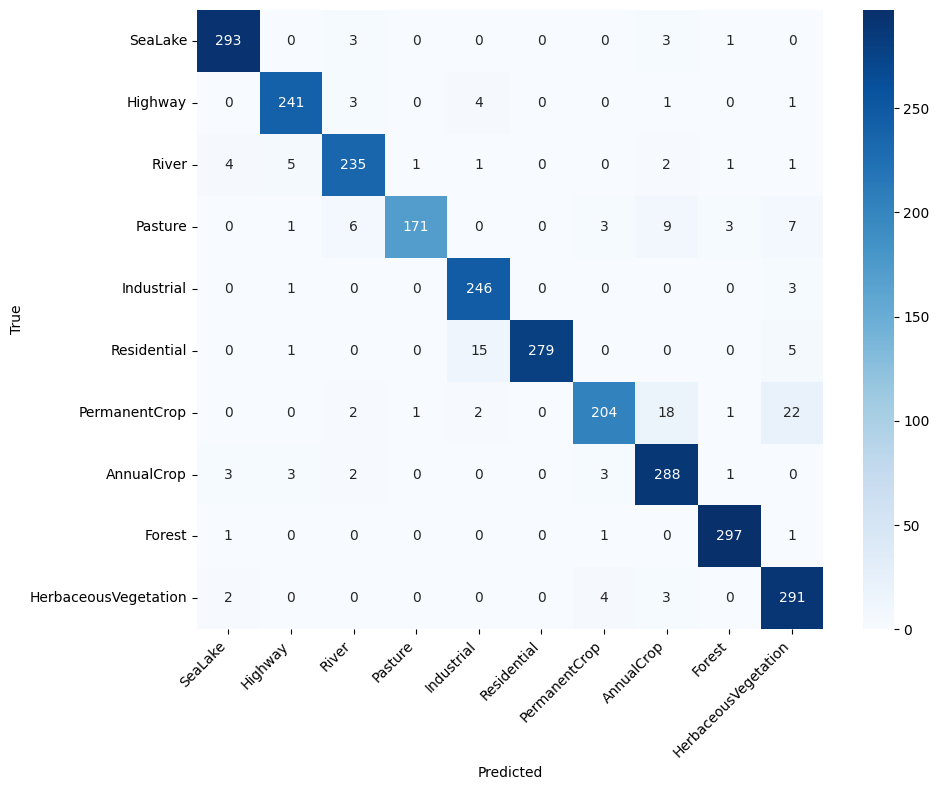

In [ ]:
#confusion matrix/ report ig
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.metrics import confusion_matrix, classification_report
all_predictions=[]
all_labels=[]
model.eval()
with torch.no_grad():
  for inputs, labels in test_loader:
    inputs, labels=inputs.to(device), labels.to(device)
    outputs=model(inputs)
    logit, predictions = torch.max(outputs,1)

    all_predictions.extend(predictions.cpu().numpy())
    all_labels.extend(labels.cpu().numpy())

class_names=[index_to_label[i] for i in range(len(index_to_label))]

print("Classification Report:")
print(classification_report(all_labels, all_predictions, target_names=class_names))

conf_matrix = confusion_matrix(all_labels, all_predictions)
plt.figure(figsize=(10, 8))
sb.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()



In [ ]:
torch.save(model.state_dict(), 'eurosat_resnet18.pth')